# T-learner and S-learner: cross-fitted CATE vs placebo

A T-learner and S-learner fit two risk models with three classifiers (logistic regression, random forest, gradient boosting):
one on the patients who received aspirin, one on those who did not. For each
patient, the CATE is the predicted risk under treatment minus the predicted risk
without it.

Each patient's CATE is predicted by a T-learner and S-learner fitted on the other folds
(5-fold cross-fitting), so no patient is scored by a model that saw him.

As a reference, the same procedure is run with the treatment labels randomly
permuted across patients (placebo): any heterogeneity it finds is estimation
noise. The question is whether the true CATE shows more structure than the
placebo, judged on the uplift-by-decile curve. The test set is not used.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

from ml_med.modeling import (
    cross_fit_cate,
    prepare_data,
    split_train_test,
    uplift_by_decile,
)

FEATURES_PATH = Path("../data/processed/ist_features.parquet")

In [2]:
df = pd.read_parquet(FEATURES_PATH)
X, y, t = prepare_data(df, "RXASP")
X_train, X_test, y_train, y_test, t_train, t_test = split_train_test(X, y, t)

In [3]:
candidates = {
    "logistic": None,
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, random_state=0, n_jobs=-1
    ),
    "gradient_boosting": HistGradientBoostingClassifier(random_state=0),
}

In [4]:
cates = {}

t_placebo = t_train.sample(frac=1, random_state=0).set_axis(t_train.index)
cates["placebo"] = cross_fit_cate(X_train, y_train, t_placebo, "RXASP")

for learner in ("t", "s"):
    for name, clf in candidates.items():
        cates[f"{learner}_{name}"] = cross_fit_cate(
            X_train, y_train, t_train, "RXASP", clf=clf, learner=learner
        )
pd.DataFrame({name: c.describe() for name, c in cates.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting
count,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000
mean,-0.003,-0.012,-0.014,-0.013,-0.013,-0.004,-0.006
std,0.052,0.050,0.047,0.133,0.006,0.009,0.020
min,-0.348,-0.356,-0.203,-0.731,-0.022,-0.045,-0.143
25%,-0.029,-0.041,-0.045,-0.085,-0.019,-0.009,-0.013
50%,-0.001,-0.013,-0.012,-0.006,-0.013,-0.003,-0.001
75%,0.025,0.013,0.018,0.057,-0.007,0.002,0.001
max,0.483,0.332,0.184,0.622,-0.000,0.029,0.313


In [5]:
uplifts = {}
uplifts["placebo"] = uplift_by_decile(cates["placebo"], y_train, t_placebo)

for name, cate in cates.items():
    t = t_placebo if name == "placebo" else t_train
    uplifts[name] = uplift_by_decile(cate, y_train, t)

pd.DataFrame({name: u["uplift"] for name, u in uplifts.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting
decile,,,,,,,
1,-0.004,0.016,-0.006,0.011,-0.011,0.017,-0.006
2,-0.027,-0.037,0.018,-0.068,0.029,-0.015,0.003
3,0.009,-0.032,-0.006,0.008,0.017,-0.043,-0.016
4,0.029,-0.040,-0.024,-0.010,-0.017,-0.008,0.032
5,-0.002,-0.012,-0.012,0.009,-0.031,-0.006,-0.057
6,0.016,-0.031,-0.021,-0.017,-0.031,-0.011,-0.033
7,-0.010,-0.009,-0.015,0.012,-0.056,-0.016,-0.032
8,0.018,0.001,-0.022,-0.019,-0.036,-0.000,0.013
9,-0.019,-0.005,-0.008,-0.029,0.021,0.010,-0.035


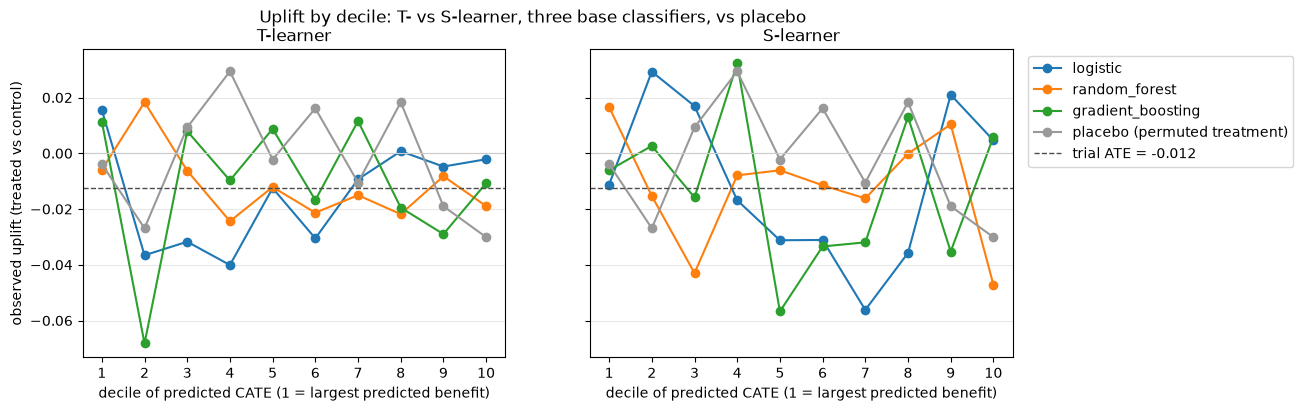

In [8]:
ate = y_train[t_train == 1].mean() - y_train[t_train == 0].mean()
colors = {
    "logistic": "tab:blue",
    "random_forest": "tab:orange",
    "gradient_boosting": "tab:green",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, learner in zip(axes, ("t", "s")):
    for clf_name, color in colors.items():
        u = uplifts[f"{learner}_{clf_name}"]
        ax.plot(u.index, u["uplift"], marker="o", color=color, label=clf_name)
    u = uplifts["placebo"]
    ax.plot(
        u.index,
        u["uplift"],
        marker="o",
        color="0.6",
        label="placebo (permuted treatment)",
    )
    ax.axhline(
        ate, linestyle="--", color="0.3", linewidth=1, label=f"trial ATE = {ate:.3f}"
    )
    ax.axhline(0, color="0.8", linewidth=0.8)
    ax.set_xticks(u.index)
    ax.set_xlabel("decile of predicted CATE (1 = largest predicted benefit)")
    ax.set_title(f"{learner.upper()}-learner")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("observed uplift (treated vs control)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Uplift by decile: T- vs S-learner, three base classifiers, vs placebo")
plt.show()

## Conclusion

1. The T-learner recovers the average effect. The mean cross-fitted CATE is
−0.012, the same as the trial ATE (observed outcome rate in treated minus
controls). As an estimator of the average effect, the T-learner works.

2. The individual CATE is estimation noise. The spread of the predicted CATE
(std ≈ 0.05) is the same with the true treatment and with a permuted one, and
the uplift-by-decile curve is indistinguishable from the placebo curve: it
bounces around the ATE with the same amplitude, and decile 1, where the model
promises the largest benefit, shows no benefit at all. A single placebo is one
draw of noise; a bootstrap band (later) will make this comparison sharper.

3. The predicted CATE tracks baseline risk, not response. Control-arm outcome
rates are highest in the middle deciles. The difference of two logistic
predictions is mechanically largest where risk is near 0.5, so a T-learner on
the probability scale "finds" heterogeneity for a geometric reason, not a
clinical one.

4. The verdict does not depend on the base classifier. Random forest and
gradient boosting give uplift curves as flat as the logistic one. The
gradient-boosting T-learner is instructive: its predicted CATE spans ±0.7
(std 0.13, almost three times the others) yet its uplift curve is no steeper.
The spread of the predicted CATE measures how much the two arm models
disagree, and an overfitting learner disagrees more; it is not a measure of
heterogeneity.

5. S-learner: narrow spread, same flat curve. The S-learner predicts a much narrower CATE distribution (std 0.006 to 0.020 vs 0.05 to 0.13 for the T-learner), but its uplift-by-decile curve is as flat as the others.

6. Verdict after six learners. Neither meta-learner, with any of the three base classifiers, finds a CATE ordering that beats a permuted treatment. The next candidate is a method built for this problem, the causal forest.

This is the baseline. Any learner that claims heterogeneous effects must beat
this curve on the same metre: cross-fitted CATE, uplift by decile, placebo.

